<a href="https://colab.research.google.com/github/helix0931-pixel/lung-Cancer-Differential-Gene-Expression-Analysis/blob/main/disease_gene_expression_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

D1 - Disease Gene Expression Signature Analyzer

In [234]:
import pandas as pb
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [235]:
#basic test database
test_data = {
    "gene": ["gene_a","gene_b","gene_c","gene_d"],
    "control": [5.0,8.0,5.0,7.0],
    "disease": [9.0,3.0,5.2,2.0]
}
data = pb.DataFrame(test_data)
display(data)

,gene,control,disease
0,gene_a,5.0,9.0
1,gene_b,8.0,3.0
2,gene_c,5.0,5.2
3,gene_d,7.0,2.0


In [236]:
replicate_data = {
    "gene": ["gene_a", "gene_b", "gene_c", "gene_d"],
    "control_1": [5.0, 8.0, 5.0, 7.0],
    "control_2": [5.2, 7.8, 5.1, 6.8],
    "control_3": [4.9, 8.2, 4.8, 7.1],
    "disease_1": [9.0, 3.0, 5.2, 2.0],
    "disease_2": [8.8, 3.2, 5.1, 2.2],
    "disease_3": [9.2, 2.8, 5.3, 1.8]
}

replicate_df = pb.DataFrame(replicate_data)

display(replicate_df)

,gene,control_1,control_2,control_3,disease_1,disease_2,disease_3
0,gene_a,5.0,5.2,4.9,9.0,8.8,9.2
1,gene_b,8.0,7.8,8.2,3.0,3.2,2.8
2,gene_c,5.0,5.1,4.8,5.2,5.1,5.3
3,gene_d,7.0,6.8,7.1,2.0,2.2,1.8


In [237]:
print(data.shape)
print(data.columns)

(4, 3)
Index(['gene', 'control', 'disease'], dtype='object')


In [238]:
data["difference"] = data["disease"]-data["control"]
display(data)

,gene,control,disease,difference
0,gene_a,5.0,9.0,4.0
1,gene_b,8.0,3.0,-5.0
2,gene_c,5.0,5.2,0.2
3,gene_d,7.0,2.0,-5.0


In [239]:
data["foldchange"] = data["disease"]/data["control"]
display(data)

,gene,control,disease,difference,foldchange
0,gene_a,5.0,9.0,4.0,1.800000
1,gene_b,8.0,3.0,-5.0,0.375000
2,gene_c,5.0,5.2,0.2,1.040000
3,gene_d,7.0,2.0,-5.0,0.285714


In [240]:
data["log2_foldchange"] = np.log2(data["foldchange"])
display(data)

,gene,control,disease,difference,foldchange,log2_foldchange
0,gene_a,5.0,9.0,4.0,1.800000,0.847997
1,gene_b,8.0,3.0,-5.0,0.375000,-1.415037
2,gene_c,5.0,5.2,0.2,1.040000,0.056584
3,gene_d,7.0,2.0,-5.0,0.285714,-1.807355


In [241]:
data_sorted = data.sort_values(
    by= "log2_foldchange",
    ascending=False
)
display(data_sorted)

,gene,control,disease,difference,foldchange,log2_foldchange
0,gene_a,5.0,9.0,4.0,1.800000,0.847997
2,gene_c,5.0,5.2,0.2,1.040000,0.056584
1,gene_b,8.0,3.0,-5.0,0.375000,-1.415037
3,gene_d,7.0,2.0,-5.0,0.285714,-1.807355


In [242]:
import numpy as np

data["regulation"] = np.where(
    data["difference"] > 0,
    "Upregulated",
    "Not upregulated"
)

display(data)

,gene,control,disease,difference,foldchange,log2_foldchange,regulation
0,gene_a,5.0,9.0,4.0,1.800000,0.847997,Upregulated
1,gene_b,8.0,3.0,-5.0,0.375000,-1.415037,Not upregulated
2,gene_c,5.0,5.2,0.2,1.040000,0.056584,Upregulated
3,gene_d,7.0,2.0,-5.0,0.285714,-1.807355,Not upregulated


In [243]:
#compare magnitudes
data["log2_foldchange_abs"] = abs(data["log2_foldchange"])
ranked_genes = data.sort_values(by="log2_foldchange_abs",
                 ascending=False
)
display(ranked_genes)


,gene,control,disease,difference,foldchange,log2_foldchange,regulation,log2_foldchange_abs
3,gene_d,7.0,2.0,-5.0,0.285714,-1.807355,Not upregulated,1.807355
1,gene_b,8.0,3.0,-5.0,0.375000,-1.415037,Not upregulated,1.415037
0,gene_a,5.0,9.0,4.0,1.800000,0.847997,Upregulated,0.847997
2,gene_c,5.0,5.2,0.2,1.040000,0.056584,Upregulated,0.056584


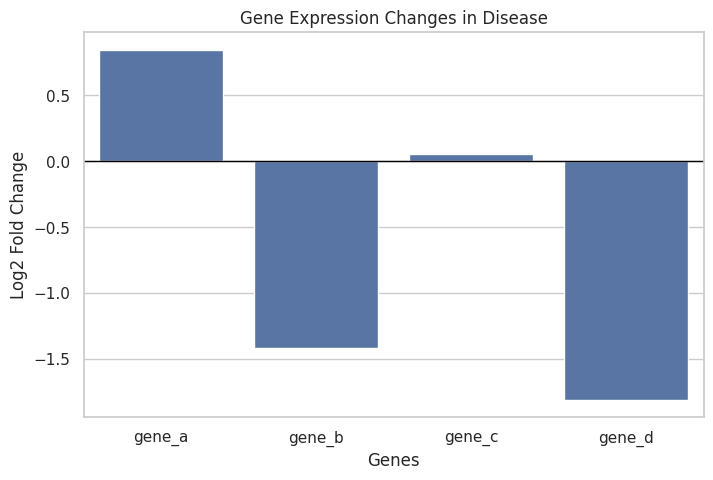

In [244]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=data,
    x="gene",
    y="log2_foldchange"
)

plt.axhline(y=0, color="black", linewidth=1)

plt.xlabel("Genes")
plt.ylabel("Log2 Fold Change")
plt.title("Gene Expression Changes in Disease")

plt.show()

In [245]:
replicate_df[["control_1", "control_2", "control_3"]].mean(axis=1)

,0
0,5.033333
1,8.000000
2,4.966667
3,6.966667


In [246]:
control_columns = ["control_1", "control_2", "control_3"]

disease_columns = ["disease_1", "disease_2", "disease_3"]

replicate_df["control_mean"] = replicate_df[control_columns].mean(axis=1)

replicate_df["disease_mean"] = replicate_df[disease_columns].mean(axis=1)

display(replicate_df)

,gene,control_1,control_2,control_3,disease_1,disease_2,disease_3,control_mean,disease_mean
0,gene_a,5.0,5.2,4.9,9.0,8.8,9.2,5.033333,9.0
1,gene_b,8.0,7.8,8.2,3.0,3.2,2.8,8.000000,3.0
2,gene_c,5.0,5.1,4.8,5.2,5.1,5.3,4.966667,5.2
3,gene_d,7.0,6.8,7.1,2.0,2.2,1.8,6.966667,2.0


In [247]:
replicate_df["fold_change"] = (
    replicate_df["disease_mean"] /
    replicate_df["control_mean"]
)
replicate_df["log2_foldchange"] = np.log2(
    replicate_df["fold_change"]
)
display(replicate_df[
    ["gene", "control_mean", "disease_mean",
     "fold_change", "log2_foldchange"]
])

,gene,control_mean,disease_mean,fold_change,log2_foldchange
0,gene_a,5.033333,9.0,1.788079,0.838411
1,gene_b,8.000000,3.0,0.375000,-1.415037
2,gene_c,4.966667,5.2,1.046980,0.066234
3,gene_d,6.966667,2.0,0.287081,-1.800469


# FINAL model with own dataset

In [248]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# Number of genes
n_genes = 500

# Generate gene names
genes = [f"GENE_{i}" for i in range(1, n_genes + 1)]

replicate_data = []

for gene in genes:

    # Baseline expression
    control_mean = np.random.uniform(20, 500)

    # Decide gene regulation category
    category = np.random.choice(
        ["Upregulated", "Downregulated", "Unchanged"],
        p=[0.20, 0.20, 0.60]
    )

    # Assign disease expression
    if category == "Upregulated":
        disease_mean = control_mean * np.random.uniform(2.5, 8)

    elif category == "Downregulated":
        disease_mean = control_mean * np.random.uniform(0.1, 0.4)

    else:
        disease_mean = control_mean * np.random.uniform(0.85, 1.15)

    # Generate biological replicates
    control_values = np.random.normal(
        control_mean,
        control_mean * 0.15,
        3
    )

    disease_values = np.random.normal(
        disease_mean,
        disease_mean * 0.15,
        3
    )

    # Avoid negative expression values
    control_values = np.clip(control_values, 0.1, None)
    disease_values = np.clip(disease_values, 0.1, None)

    replicate_data.append({
        "gene": gene,
        "control_1": control_values[0],
        "control_2": control_values[1],
        "control_3": control_values[2],
        "disease_1": disease_values[0],
        "disease_2": disease_values[1],
        "disease_3": disease_values[2]
    })

replicate_data = pd.DataFrame(replicate_data)

display(replicate_data.head())
print("Total genes:", len(replicate_data))

,gene,control_1,control_2,control_3,disease_1,disease_2,disease_3
0,GENE_1,166.459669,209.335763,208.141256,246.073101,195.064917,196.850509
1,GENE_2,80.081656,98.922225,91.621110,29.121829,24.022958,21.919287
2,GENE_3,330.638064,253.041737,243.293565,200.580560,197.814791,248.282293
3,GENE_4,66.747205,56.271244,75.134708,53.653708,67.739568,46.374592
4,GENE_5,291.683140,319.775101,239.672910,1686.756627,2468.850866,2033.557497


Total genes: 500


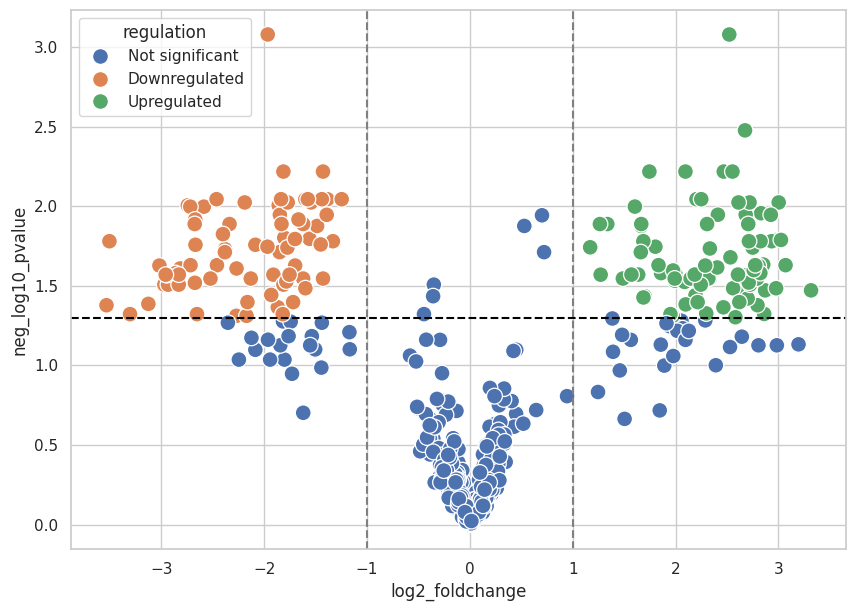

In [249]:
# 1. Import libraries

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# 2. Create DataFrame
replicate_df = pb.DataFrame(replicate_data)

# 3. Define control and disease columns
control_columns = ["control_1", "control_2", "control_3"]
disease_columns = ["disease_1", "disease_2", "disease_3"]


# 4. Calculate mean expression
replicate_df["control_mean"] = replicate_df[control_columns].mean(axis=1)
replicate_df["disease_mean"] = replicate_df[disease_columns].mean(axis=1)


# 5. Calculate log2 fold change
replicate_df["fold_change"] = (
    replicate_df["disease_mean"] / replicate_df["control_mean"]
)

replicate_df["log2_foldchange"] = np.log2(
    replicate_df["fold_change"]
)


# 6. Perform Welch's t-test
p_values = []

for _, row in replicate_df.iterrows():

    control_values = row[control_columns].to_numpy(dtype=float)
    disease_values = row[disease_columns].to_numpy(dtype=float)

    statistic, p_value = ttest_ind(
        disease_values,
        control_values,
        equal_var=False
    )

    p_values.append(p_value)

replicate_df["p_value"] = p_values


# 7. Adjust p-values using Benjamini-Hochberg
replicate_df["adjusted_p_value"] = multipletests(
    replicate_df["p_value"],
    method="fdr_bh"
)[1]


# 8. Calculate -log10 adjusted p-value
replicate_df["neg_log10_pvalue"] = -np.log10(
    replicate_df["adjusted_p_value"].clip(lower=1e-300)
)


# 9. Classify genes
replicate_df["regulation"] = np.where(
    (replicate_df["log2_foldchange"] >= 1) &
    (replicate_df["adjusted_p_value"] < 0.05),
    "Upregulated",
    np.where(
        (replicate_df["log2_foldchange"] <= -1) &
        (replicate_df["adjusted_p_value"] < 0.05),
        "Downregulated",
        "Not significant"
    )
)


# 10. Plot volcano plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=replicate_df,
    x="log2_foldchange",
    y="neg_log10_pvalue",
    hue="regulation",
    s=130
)

# Threshold lines
plt.axvline(x=1, linestyle="--", color="grey")
plt.axvline(x=-1, linestyle="--", color="grey")
plt.axhline(
    y=-np.log10(0.05),
    linestyle="--",
    color="black"
)



FINAL VERSION

In [250]:
# 1. Import libraries

import pandas as pd
import numpy as np
import requests
import gzip
import io
import csv
import os
import time


# 2. Define GEO download URL

matrix_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE10nnn/GSE10072/matrix/"
    "GSE10072_series_matrix.txt.gz"
)

file_path = "/content/GSE10072_series_matrix.txt.gz"


# 3. Download with automatic retries

max_retries = 5

for attempt in range(max_retries):

    try:

        print(f"Download attempt {attempt + 1}/{max_retries}")

        with requests.get(
            matrix_url,
            stream=True,
            timeout=(30, 180),
            headers={"User-Agent": "Mozilla/5.0"}
        ) as response:

            response.raise_for_status()

            expected_size = int(
                response.headers.get("Content-Length", 0)
            )

            downloaded_size = 0

            with open(file_path, "wb") as f:

                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):

                    if chunk:
                        f.write(chunk)
                        downloaded_size += len(chunk)

            # Check downloaded file size
            if expected_size and downloaded_size != expected_size:
                raise IOError("Incomplete download detected")

        # Verify gzip file integrity
        with gzip.open(file_path, "rb") as f:
            while f.read(1024 * 1024):
                pass

        print("Download successful!")
        break

    except Exception as e:

        print("Download failed:", str(e))

        if os.path.exists(file_path):
            os.remove(file_path)

        if attempt == max_retries - 1:
            raise RuntimeError(
                "Download failed after 5 attempts. "
                "Please try again later."
            )

        time.sleep(5 * (attempt + 1))


# 4. Decompress downloaded file

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    geo_text = f.read()


# 5. Extract sample titles

title_line = next(
    line for line in geo_text.splitlines()
    if line.startswith("!Sample_title\t")
)

sample_titles = next(
    csv.reader([title_line], delimiter="\t")
)[1:]


# 6. Read expression matrix

expression_df = pd.read_csv(
    io.StringIO(geo_text),
    sep="\t",
    comment="!",
    index_col=0
)


# 7. Identify cancer and normal samples

tumor_columns = [
    sample
    for sample, title in zip(expression_df.columns, sample_titles)
    if "Lung Tumor" in title
]

normal_columns = [
    sample
    for sample, title in zip(expression_df.columns, sample_titles)
    if "Normal Lung" in title
]


# 8. Display dataset information

print("\nDATASET INFORMATION")
print("--------------------------------")

print("Dataset: GSE10072")

print("Downloaded size:", round(downloaded_size / 1024 / 1024, 2), "MB")

print("Expression matrix shape:", expression_df.shape)

print("Tumor samples:", len(tumor_columns))

print("Normal samples:", len(normal_columns))

print("Total identified samples:", len(tumor_columns) + len(normal_columns))


# 9. Display first five rows

display(expression_df.head())

Download attempt 1/5
Download successful!

DATASET INFORMATION
--------------------------------
Dataset: GSE10072
Downloaded size: 12.42 MB
Expression matrix shape: (22283, 107)
Tumor samples: 58
Normal samples: 49
Total identified samples: 107


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,10.927084,10.416978,10.628538,10.151180,10.988512,10.778205,10.568814,10.479425,10.548843,10.465005,...,10.727493,10.740353,10.527962,10.193615,10.768815,10.467693,10.902778,10.869402,10.292285,10.407218
1053_at,6.895217,6.924856,7.550245,6.699557,6.826031,6.718372,6.739765,6.724615,7.102475,6.627922,...,6.856575,6.737879,6.959032,7.008578,6.740444,6.795750,6.838162,6.628363,6.794050,6.358410
117_at,8.110190,7.760228,7.974676,7.712676,7.775592,7.777087,7.893210,8.058398,8.005438,7.961476,...,7.741922,7.805107,8.093078,8.144760,8.159483,7.855457,8.010428,7.889019,8.163266,7.973844
121_at,9.451286,9.520943,9.807597,9.522087,9.855061,9.861055,10.126183,9.878970,10.110318,10.411478,...,10.089149,10.007059,9.832610,10.107004,9.790645,9.645239,9.871851,9.867988,9.824801,9.850144
1255_g_at,4.814477,4.718640,4.905163,4.818076,4.823958,4.848313,5.125956,5.037979,4.889936,5.177818,...,5.048391,4.758050,4.900470,4.948760,4.609322,4.759571,4.788774,4.967626,4.817474,5.128892


In [251]:
# 1. Import libraries

import pandas as pd
import numpy as np
import requests
import gzip
import io
import os
import re
import time


# 2. Function to download files with retries

def download_file(url, path):

    for attempt in range(5):

        try:

            print(f"Download attempt {attempt + 1}/5")

            with requests.get(
                url,
                stream=True,
                timeout=(30, 180),
                headers={"User-Agent": "Mozilla/5.0"}
            ) as response:

                response.raise_for_status()

                with open(path, "wb") as f:

                    for chunk in response.iter_content(1024 * 1024):

                        if chunk:
                            f.write(chunk)

            # Verify compressed file
            with gzip.open(path, "rb") as f:
                while f.read(1024 * 1024):
                    pass

            return

        except Exception as e:

            print("Download error:", e)

            if os.path.exists(path):
                os.remove(path)

            if attempt == 4:
                raise

            time.sleep(5 * (attempt + 1))


# 3. Download GPL96 annotation

annotation_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/platforms/"
    "GPLnnn/GPL96/annot/GPL96.annot.gz"
)

annotation_path = "/content/GPL96.annot.gz"

if not os.path.exists(annotation_path):

    download_file(annotation_url, annotation_path)


# 4. Decompress annotation file

with gzip.open(
    annotation_path,
    "rt",
    encoding="utf-8",
    errors="replace"
) as f:

    annotation_lines = f.readlines()


# 5. Find annotation table header

header_index = next(
    (
        i for i, line in enumerate(annotation_lines)
        if line.startswith("#ID\t") or line.startswith("ID\t")
    ),
    None
)


# 6. Read annotation table

if header_index is None:

    annotation_df = pd.DataFrame()

else:

    annotation_df = pd.read_csv(
        io.StringIO("".join(annotation_lines[header_index:])),
        sep="\t",
        low_memory=False
    )

    annotation_df.columns = (
        annotation_df.columns
        .str.strip()
        .str.lstrip("#")
    )


# 7. Automatically detect gene symbol column

def normalize_column(column):

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(column).lower()
    )


column_lookup = {
    normalize_column(col): col
    for col in annotation_df.columns
}

gene_symbol_column = None

for possible_name in [
    "Gene Symbol",
    "Gene.Symbol",
    "GeneSymbol",
    "gene_symbol",
    "Symbol"
]:

    key = normalize_column(possible_name)

    if key in column_lookup:

        gene_symbol_column = column_lookup[key]
        break


# 8. Fallback: download full GPL96 SOFT annotation

if gene_symbol_column is None:

    print("Gene Symbol column not found.")
    print("Downloading full GPL96 platform annotation...")

    soft_url = (
        "https://ftp.ncbi.nlm.nih.gov/geo/platforms/"
        "GPLnnn/GPL96/soft/GPL96_family.soft.gz"
    )

    soft_path = "/content/GPL96_family.soft.gz"

    download_file(soft_url, soft_path)

    with gzip.open(
        soft_path,
        "rt",
        encoding="utf-8",
        errors="replace"
    ) as f:

        soft_lines = f.readlines()

    table_start = next(
        i for i, line in enumerate(soft_lines)
        if line.strip() == "!platform_table_begin"
    )

    table_end = next(
        i for i, line in enumerate(soft_lines)
        if line.strip() == "!platform_table_end"
    )

    annotation_df = pd.read_csv(
        io.StringIO(
            "".join(soft_lines[table_start + 1:table_end])
        ),
        sep="\t",
        low_memory=False
    )

    annotation_df.columns = annotation_df.columns.str.strip()

    column_lookup = {
        normalize_column(col): col
        for col in annotation_df.columns
    }

    gene_symbol_column = column_lookup.get("genesymbol")


# 9. Verify required columns

id_column = column_lookup.get("id")

if id_column is None or gene_symbol_column is None:

    print("Available annotation columns:")
    print(annotation_df.columns.tolist())

    raise ValueError(
        "Could not identify probe ID and gene symbol columns."
    )


# 10. Extract probe IDs and gene symbols

annotation_df = annotation_df[
    [id_column, gene_symbol_column]
].copy()

annotation_df.columns = ["ID", "gene"]

annotation_df["ID"] = annotation_df["ID"].astype(str).str.strip()

annotation_df["gene"] = (
    annotation_df["gene"]
    .fillna("")
    .astype(str)
    .str.split(" /// ")
    .str[0]
    .str.strip()
)


# 11. Remove missing gene symbols

annotation_df = annotation_df[
    (annotation_df["gene"] != "") &
    (annotation_df["gene"] != "---") &
    (annotation_df["gene"].str.lower() != "nan")
]


# 12. Match probes with expression data

expression_df.index = expression_df.index.astype(str).str.strip()

expression_df.index.name = "ID"

expression_df = expression_df.reset_index()

expression_df = expression_df.merge(
    annotation_df[["ID", "gene"]],
    on="ID",
    how="inner"
)


# 13. Remove probe ID column

expression_df = expression_df.drop(columns=["ID"])


# 14. Combine multiple probes belonging to the same gene

expression_df = expression_df.groupby(
    "gene"
).mean(numeric_only=True)


# 15. Display final results

print("\nGENE ANNOTATION RESULTS")
print("--------------------------------")

print("Annotation column used:", gene_symbol_column)

print("Total annotated genes:", expression_df.shape[0])

print("Total samples:", expression_df.shape[1])

display(expression_df.head(10))


GENE ANNOTATION RESULTS
--------------------------------
Annotation column used: Gene symbol
Total annotated genes: 13299
Total samples: 107


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
gene,,,,,,,,,,,,,,,,,,,,,
A1CF,6.959175,7.330048,8.036416,7.638816,8.040167,7.713143,8.249392,7.690561,7.991688,8.039479,...,7.706524,7.340340,7.699080,7.748167,7.320514,7.453062,7.103039,7.904781,7.550336,7.566240
A2M,13.059984,13.702212,11.107587,13.481028,12.193454,12.622631,11.673432,13.257820,10.630255,13.206344,...,12.190341,13.453006,11.426576,13.155146,13.212162,13.486828,12.688802,12.638673,13.606686,13.439991
A4GALT,5.231963,5.396363,5.916574,5.339658,5.370519,5.432144,5.494388,5.532268,6.086038,5.616682,...,6.180514,5.907535,6.097793,5.993684,5.894666,5.954336,5.872981,5.956118,5.731357,5.943617
A4GNT,6.015383,6.224329,6.332004,6.231816,6.207646,6.122445,6.276097,6.295252,6.386315,6.651137,...,6.392070,6.286967,6.318307,6.528481,6.112522,6.298671,6.272332,6.347546,6.109810,6.355032
AAAS,8.767797,8.795224,9.060626,8.852229,9.151269,9.169505,9.016843,9.023949,9.098804,9.402499,...,9.597385,9.135215,9.142370,9.272234,9.101806,9.110091,9.393780,9.195473,9.190903,9.157074
AACS,7.762807,8.001055,9.472215,7.711807,7.477610,9.035549,8.233345,8.116852,8.074831,7.406252,...,8.094017,7.647584,8.909882,7.792868,7.814708,7.801156,7.792160,7.862585,7.596014,7.620618
AADAC,7.118915,7.268733,7.347736,7.734262,7.083809,7.448092,6.999450,7.196872,7.454517,7.604106,...,7.319078,7.399448,8.242322,7.843945,7.976632,7.572265,7.353882,7.220265,7.802635,7.672319
AAGAB,7.490779,7.642617,7.646721,7.407622,7.528351,7.791381,7.796218,7.668465,7.655364,7.772242,...,7.948255,7.834984,7.990080,8.026422,7.703027,7.825481,8.103368,7.651805,7.467603,7.926522
AAK1,6.594705,6.809936,6.936388,6.887179,6.845795,6.800039,7.197443,6.959413,6.934217,7.145928,...,6.750823,6.925404,6.722348,7.069366,6.770981,6.665194,6.675649,6.914670,6.945374,6.997310


In [252]:
# 1. Import libraries

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# 2. Create DataFrame

replicate_df = expression_df.copy()


# 3. Define control and disease columns

control_columns = normal_columns
disease_columns = tumor_columns


# 4. Calculate mean expression

replicate_df["control_mean"] = replicate_df[control_columns].mean(axis=1)

replicate_df["disease_mean"] = replicate_df[disease_columns].mean(axis=1)


# 5. Calculate fold change

replicate_df["log2_foldchange"] = (
    replicate_df["disease_mean"] - replicate_df["control_mean"]
)

replicate_df["fold_change"] = 2 ** replicate_df["log2_foldchange"]


# 6. Perform Welch's t-test

p_values = []

for _, row in replicate_df.iterrows():

    control_values = row[control_columns].to_numpy(dtype=float)
    disease_values = row[disease_columns].to_numpy(dtype=float)

    statistic, p_value = ttest_ind(
        disease_values,
        control_values,
        equal_var=False,
        nan_policy="omit"
    )

    p_values.append(p_value)


replicate_df["p_value"] = p_values

replicate_df["p_value"] = replicate_df["p_value"].fillna(1.0)


# 7. Adjust p-values using Benjamini-Hochberg

replicate_df["adjusted_p_value"] = multipletests(
    replicate_df["p_value"],
    method="fdr_bh"
)[1]


# 8. Calculate -log10 adjusted p-value

replicate_df["neg_log10_pvalue"] = -np.log10(
    replicate_df["adjusted_p_value"].clip(lower=1e-300)
)


# 9. Classify genes

replicate_df["regulation"] = np.where(
    (replicate_df["log2_foldchange"] >= 1) &
    (replicate_df["adjusted_p_value"] < 0.05),
    "Upregulated",

    np.where(
        (replicate_df["log2_foldchange"] <= -1) &
        (replicate_df["adjusted_p_value"] < 0.05),
        "Downregulated",
        "Not significant"
    )
)

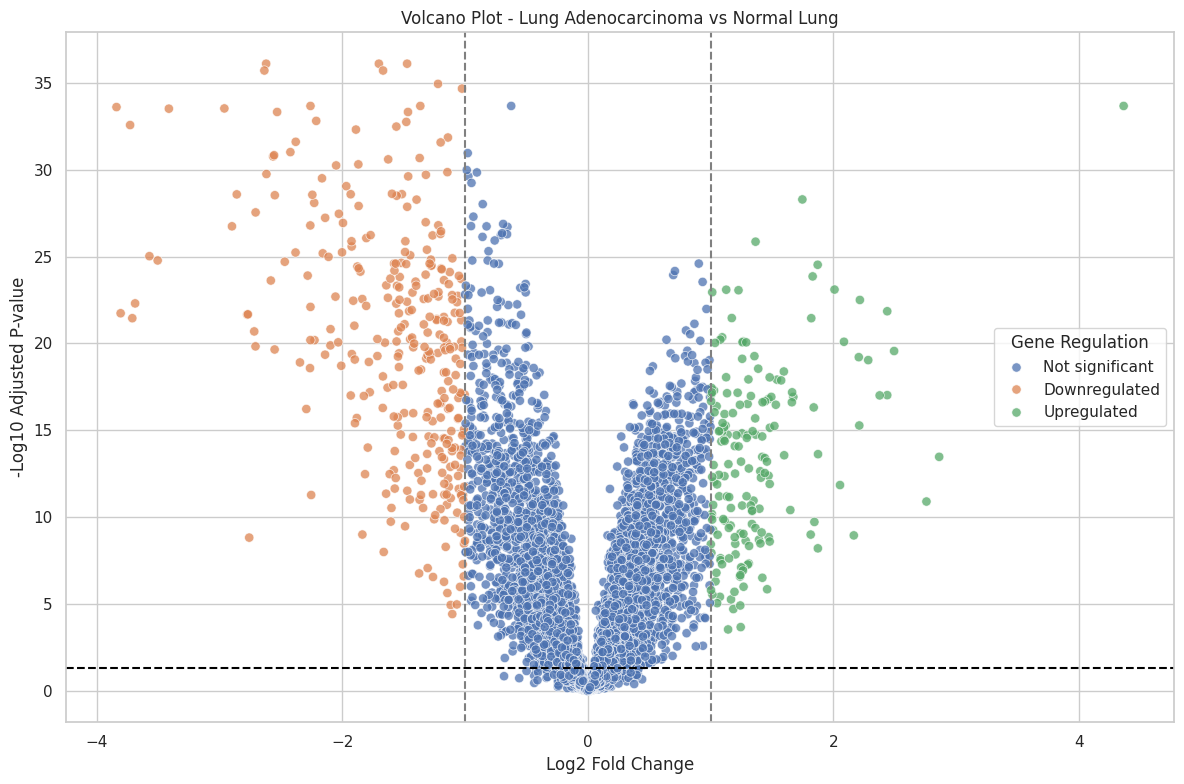

In [253]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=replicate_df,
    x="log2_foldchange",
    y="neg_log10_pvalue",
    hue="regulation",
    s=45,
    alpha=0.75
)

# Threshold lines

plt.axvline(x=1, linestyle="--", color="grey")
plt.axvline(x=-1, linestyle="--", color="grey")

plt.axhline(
    y=-np.log10(0.05),
    linestyle="--",
    color="black"
)

plt.xlabel("Log2 Fold Change")
plt.ylabel("-Log10 Adjusted P-value")

plt.title(
    "Volcano Plot - Lung Adenocarcinoma vs Normal Lung"
)

plt.legend(title="Gene Regulation")

plt.tight_layout()
plt.show()

In [254]:
display(
    replicate_df[
        [
            "control_mean",
            "disease_mean",
            "log2_foldchange",
            "fold_change",
            "p_value",
            "adjusted_p_value",
            "regulation"
        ]
    ].sort_values(
        by="adjusted_p_value"
    )
)

,control_mean,disease_mean,log2_foldchange,fold_change,p_value,adjusted_p_value,regulation
gene,,,,,,,
CD36,8.241322,6.539745,-1.701577,0.307450,1.241866e-40,7.958235e-37,Downregulated
GRK5,9.628394,8.156925,-1.471469,0.360615,1.795226e-40,7.958235e-37,Downregulated
CDH5,9.424160,6.804586,-2.619573,0.162716,1.317136e-40,7.958235e-37,Downregulated
PECAM1,11.007086,9.339830,-1.667257,0.314851,7.389988e-40,1.965589e-36,Downregulated
FAM107A,9.979727,7.345635,-2.634092,0.161087,6.056904e-40,1.965589e-36,Downregulated
...,...,...,...,...,...,...,...
LARP4B,7.605453,7.605393,-0.000060,0.999959,9.988955e-01,9.991961e-01,Not significant
RPL36A-HNRNPH2///HNRNPH2,8.496274,8.496407,0.000133,1.000092,9.990803e-01,9.993057e-01,Not significant
SNRNP70,8.066055,8.066101,0.000046,1.000032,9.993045e-01,9.994548e-01,Not significant
